# 3. Random Forest

100 decision trees, each grown on a bootstrap sample of the rows and a random subset of the features at
every split; the forest averages their probabilities, which cancels much of a single tree's variance.

From-scratch code: `ClassificationAlgorithms/RandomForest.py` · charts: `Images/Classification/03_Random_Forest/` · tables: `Results/Classification/03_Random_Forest/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from RandomForest import RandomForestClassifierScratch
from sklearn.ensemble import RandomForestClassifier

out = Outputs("Classification", "03_Random_Forest")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it
model = RandomForestClassifierScratch(n_estimators=100, max_depth=8, min_samples_leaf=10, random_state=SEED)
check_settings("Random Forest", model)
model.fit(d.X_tr, d.y_tr, feature_names=d.feature_cols)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn RandomForestClassifier with the same settings
sk = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=10, random_state=SEED, n_jobs=-1).fit(
    d.X_tr, d.y_tr
)
p_sk = sk.predict_proba(d.X_te)[:, 1]
check = sklearn_check(
    "Random Forest vs sklearn RandomForestClassifier",
    np.abs(p_te - p_sk).max(),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, p_sk),
    "max |dP|",
)

settings match Common/model_zoo.py (11 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2349        0.5000
log loss                            0.4468           NaN
accuracy                            0.4817        0.8278
precision                           0.2129        0.3239
recall / sensitivity                0.8361        0.0754
specificity                         0.4146           NaN
F1                                  0.3393        0.1223
ROC-AUC                             0.6884           NaN
PR-AUC                              0.2716           NaN
defaulters missed (FN)             50.0000           NaN

catches 83.6% of the 305 test defaulters (50 missed), flags 62.5% of applicants


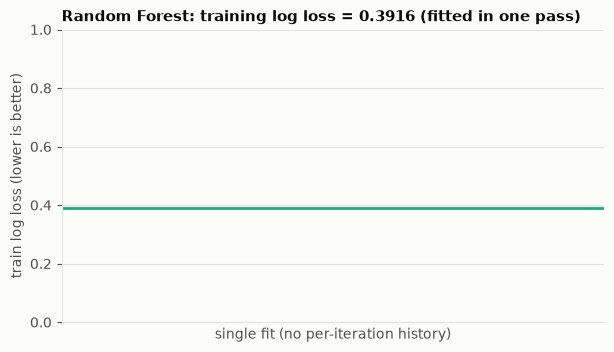

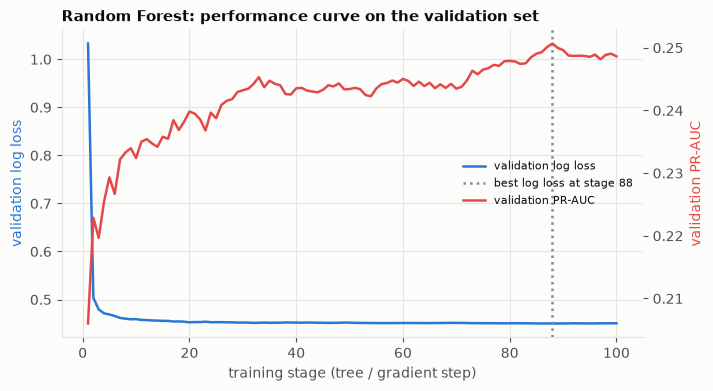

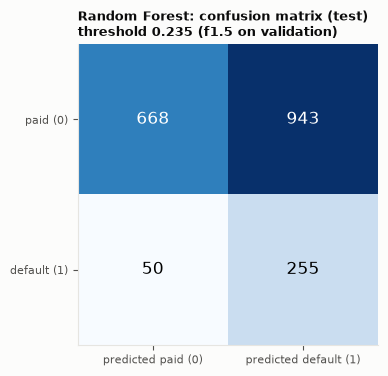

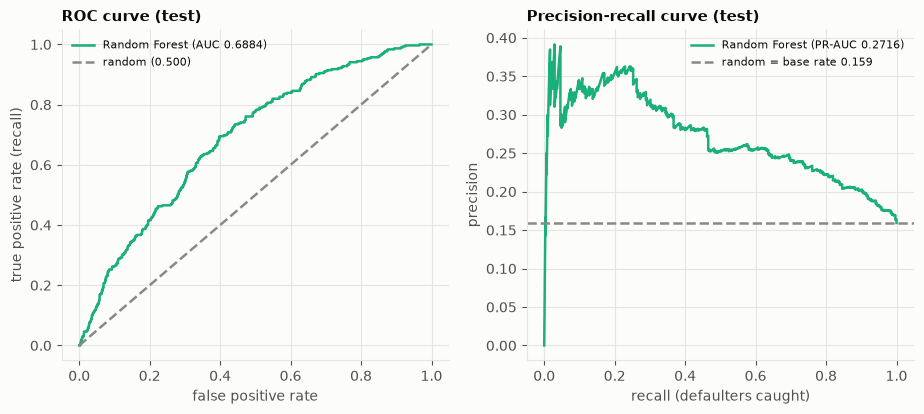

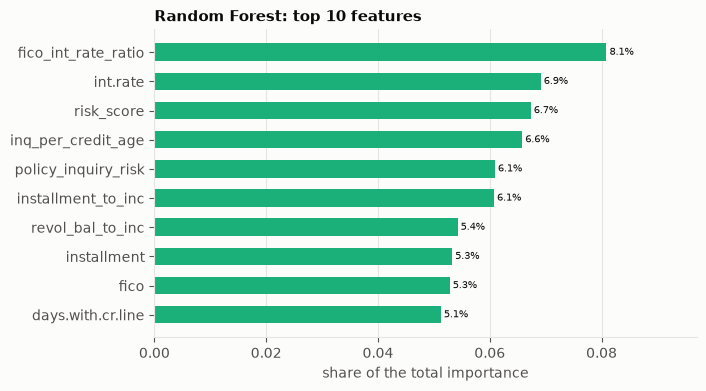


scratch vs library:
  Random Forest vs sklearn RandomForestClassifier
    AUC scratch 0.6884 | AUC library 0.6887 | max |dP| = 0.24



saved + reloaded TrainedModels/Classification/03_Random_Forest.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Random Forest", model, d, check)